In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df = df.drop(columns=["customerID"])

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", np.nan))
print("Missing values per column:")
print(df.isna().sum()[lambda s: s > 0])

print()
print("Tenure of rows with missing TotalCharges:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print()
print("Churn rate:", round(df["Churn"].mean(), 3))
df.describe(include="all").T.head(25)

Missing values per column:
TotalCharges    11
dtype: int64

Tenure of rows with missing TotalCharges: [0]

Churn rate: 0.265


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineBackup,7043,3,No,3088,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL = ["Contract", "PaymentMethod"]

X = df[NUMERIC + CATEGORICAL]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 3), " Test churn rate:", round(y_test.mean(), 3))

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

Train: (5634, 5)  Test: (1409, 5)
Train churn rate: 0.265  Test churn rate: 0.265


In [4]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
}

fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
print("Trained:", list(fitted))

Trained: ['KNN', 'SVM', 'Decision Tree']


In [5]:
rows = []
preds = {}
for name, pipe in fitted.items():
    y_pred = pipe.predict(X_test)
    preds[name] = y_pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-Score
Model,,,,
KNN,0.7835,0.6068,0.5241,0.5624
SVM,0.7779,0.6125,0.4439,0.5147
Decision Tree,0.7821,0.6184,0.4679,0.5327


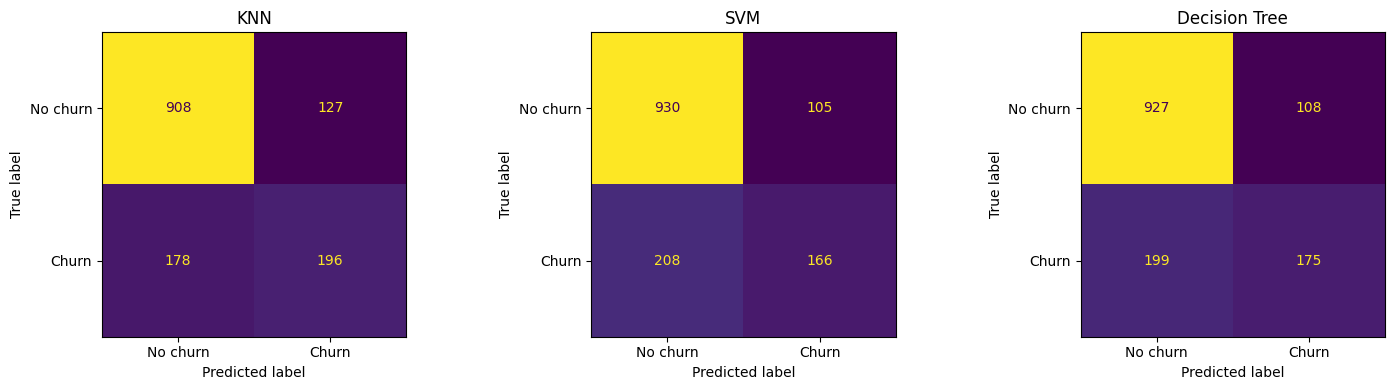

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No churn", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

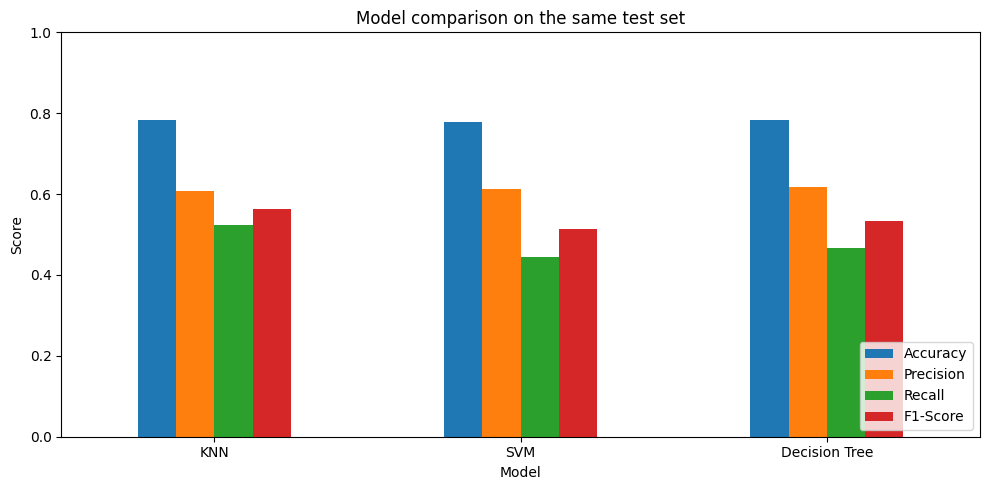

Best model by F1-Score: KNN (0.5624)


In [ ]:
ax = results.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the same test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

best = results["F1-Score"].idxmax()
print(f"Best model by F1-Score: {best} ({results.loc[best, 'F1-Score']:.4f})")